# 00 · Simulate a slice and find spatial clusters

Generate counts for DLPFC section 151675, cluster the simulated slice with GraphST, and compare its clusters with the known tissue layers. [Data and environment setup](https://github.com/maiziezhoulab/FEAST/blob/main/tutorial/README.md#setup)

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
import FEAST

TUTORIAL = Path.cwd() if Path.cwd().name == "tutorial" else Path.cwd() / "tutorial"
sys.path.insert(0, str(TUTORIAL))
from _utils import data_root, load_counts, gene_summary, spatial_panel
DATA = data_root()

OUT = TUTORIAL / "outputs" / "00"
OUT.mkdir(parents=True, exist_ok=True)
print("FEAST", FEAST.__version__)

FEAST 1.0.6


## Load the reference

Use raw counts, spot coordinates and the tissue-layer labels in `obs["ground_truth"]`.

In [2]:
reference = load_counts(DATA / "dlpfc/151675.h5ad", "ground_truth")
print(f"{reference.n_obs:,} spots × {reference.n_vars:,} genes")

3,565 spots × 18,641 genes


## Simulate counts

Hungarian assignment matches sampled gene statistics to reference genes. Reference ranks place the new counts across spots. The full assignment can use several GB of memory.

In [3]:
%%capture --no-stderr
simulated = FEAST.simulate(
    reference, seed=2026, parameter_mode="hungarian", spatial_mode="reference_rank",
    assignment_solver="scipy", assignment_blocks=False, verbose=False,
)

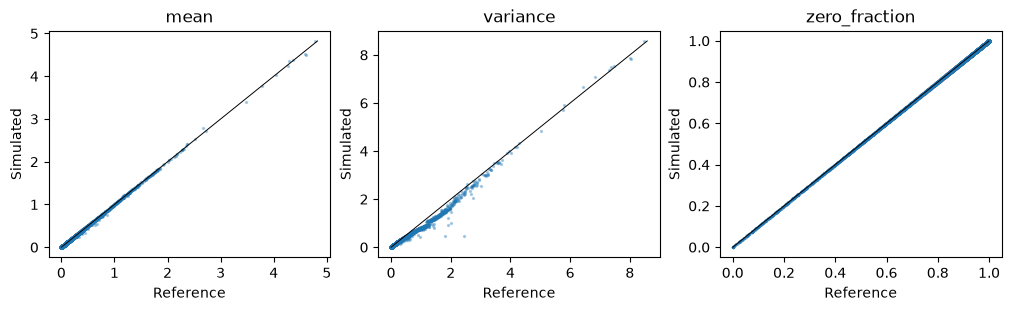

In [4]:
ref_stats, sim_stats = gene_summary(reference), gene_summary(simulated)
fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout="constrained")
for ax, key in zip(axes, ref_stats.columns):
    x, y = ref_stats[key], sim_stats[key]
    if key != "zero_fraction":
        x, y = np.log1p(x), np.log1p(y)
    ax.scatter(x, y, s=2, alpha=0.3)
    limits = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(limits, limits, color="black", linewidth=0.7)
    ax.set(title=key, xlabel="Reference", ylabel="Simulated")
plt.show()

## Prepare the GraphST input

Select 3,000 variable genes on the measured slice. Normalize the simulated panel to 10,000 counts per spot and apply `log1p` once.

In [5]:
import scanpy as sc
panel_source = reference.copy()
sc.pp.highly_variable_genes(panel_source, n_top_genes=3000, flavor="seurat_v3")
genes = panel_source.var_names[panel_source.var["highly_variable"]]
prepared = ad.AnnData(
    X=simulated[:, genes].X.copy(),
    obs=pd.DataFrame({"ground_truth": pd.Categorical(simulated.obs["ground_truth"])},
                     index=simulated.obs_names),
    var=pd.DataFrame(index=genes),
)
prepared.obsm["spatial"] = simulated.obsm["spatial"].copy()
sc.pp.normalize_total(prepared, target_sum=1e4)
sc.pp.log1p(prepared)
prepared.write_h5ad(OUT / "graphst_input.h5ad")

## Cluster the simulated slice

The GraphST worker trains for 600 epochs on CUDA. It uses mclust with the number of known layers as the cluster count. The layer labels are used for evaluation.

In [6]:
import os
import subprocess
with (OUT / "graphst.log").open("w") as log:
    subprocess.run([
        os.environ["GRAPHST_PYTHON"], str(TUTORIAL / "graphst_step.py"),
        str(OUT / "graphst_input.h5ad"), str(OUT / "graphst_result.h5ad"), "--device", "cuda",
    ], check=True, stdout=log, stderr=subprocess.STDOUT)
clustered = ad.read_h5ad(OUT / "graphst_result.h5ad")

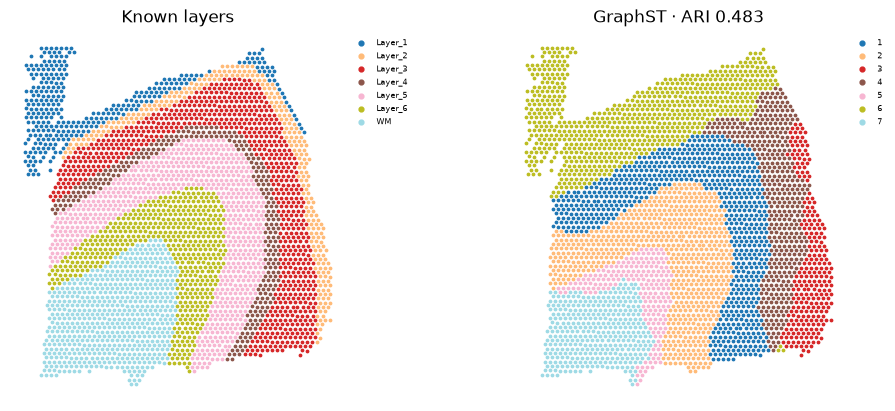

In [7]:
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(clustered.obs["ground_truth"], clustered.obs["predicted_cluster"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
spatial_panel(axes[0], clustered.obsm["spatial"], clustered.obs["ground_truth"], "Known layers", True)
spatial_panel(axes[1], clustered.obsm["spatial"], clustered.obs["predicted_cluster"], f"GraphST · ARI {ari:.3f}", True)
plt.show()

Points near the diagonal have similar measured and simulated gene statistics. The adjusted Rand index (ARI) compares clusters with known layers regardless of label names. An ARI of 1 indicates perfect agreement.